# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# seaborn no es necesario; utiliza matplotlib.pyplot para las visualizaciones
%pip install -q scikit-learn

from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

df = pd.read_csv(DATA_PATH)
print(f"Datos cargados desde: {DATA_PATH}")
df.head()

Datos cargados desde: c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture6\challenge\data\wine.csv


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("Tipos:\n", df.dtypes)
print("Nulos por columna:\n", df.isna().sum())
print("Duplicados:", df.duplicated().sum())
print("Distribución de target:\n", df["target"].value_counts().sort_index())
assert "target" in df.columns
assert df["target"].notna().all()
assert df.drop(columns="target").select_dtypes(include=np.number).shape[1] == len(df.columns) - 1

Forma: (178, 14)
Tipos:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object
Nulos por columna:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/o

**Conclusión de calidad:**

> El conjunto contiene variables numéricas, no presenta nulos y se verificó la distribución de las clases y los duplicados. Se conservan las filas válidas y se usa un split estratificado 80/20 para mantener la proporción de clases.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

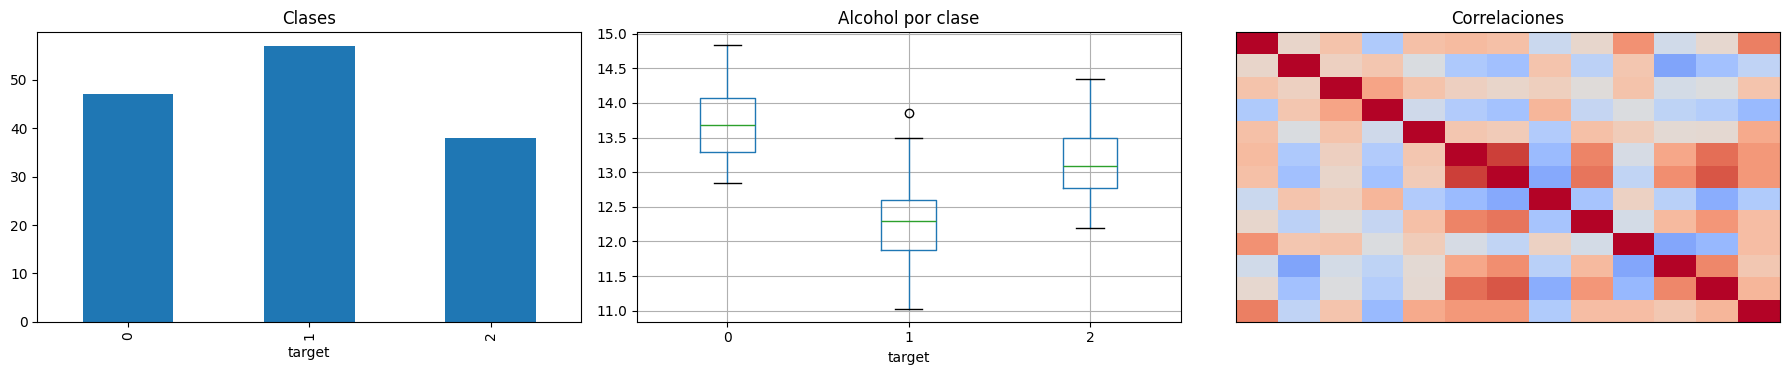

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train_df["target"].value_counts().sort_index().plot.bar(ax=axes[0], title="Clases")
train_df.boxplot(column="alcohol", by="target", ax=axes[1])
axes[1].set_title("Alcohol por clase")
axes[1].set_xlabel("target")
corr = train_df.drop(columns="target").corr()
axes[2].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axes[2].set_title("Correlaciones")
axes[2].set_xticks([])
axes[2].set_yticks([])
plt.suptitle("")
plt.tight_layout()
plt.show()

**Hallazgos:**

1. Las clases tienen escalas y tamaños diferentes, por lo que la estratificación evita un reparto sesgado.
2. Alcohol y otras variables químicas muestran diferencias visibles entre clases, lo que sugiere capacidad predictiva.
3. Hay variables con escalas muy distintas y correlaciones fuertes; los modelos sensibles a escala requieren estandarización y regularización.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)
contract = {
    "target": "target",
    "features": [column for column in df.columns if column != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)
print("Datos y contrato guardados.")

Datos y contrato guardados.


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [✓] Cargué el CSV desde `data/raw`.
- [✓] Revisé calidad y distribución de la clase.
- [✓] Realicé un split estratificado.
- [✓] No exploré el conjunto de test.
- [✓] Guardé los tres artefactos requeridos.